In [64]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh, eigh_tridiagonal
from scipy.sparse import diags
from scipy.sparse.linalg import eigsh
from scipy.optimize import brentq
from scipy.linalg import solve_banded

In [11]:
hbar =1
m_eff =1
L =1.0 # well width

def hamilton_fun(N, V_fun, solver='tridiagonal', num_levels=5):
    a = L/(N+1)  # interior grid spacing
    x = np.linspace(a,L-a,N) # interior grid points
    t = hbar**2 / (2*m_eff* a**2)
    V = V_fun(x)

    diag = 2 *t + V
    off_diag = -t*np.ones(N-1)

    if solver == 'tridiagonal':
        energies,_=eigh_tridiagonal(diag,off_diag,select='i', select_range=(0,num_levels-1))

    elif solver == 'dense':
        H = np.diag(diag)+ np.diag(off_diag,K=1) + np.diag(off_diag,k=-1)
        enrgies,_= eigh( H , subset_to_index=[0,num_levels_1])

    else:
        raise ValueError ("invalid")

    return a, energies


def V_infinite_well(x):
     return np.zeros_like(x)

N_values = [20,40,80,160,320,640]
a_values = []
errors ={n: [] for n in range(1, 6)}

def exact_energy(n):
    return ( hbar**2 / 2*m_eff) * (n**2 * np.pi**2) / L **2

for N in N_values:
     a, numerical_energies = hamilton_fun(N, V_infinite_well, solver='tridiagonal', num_levels=5 )
     a_values.append(a)

     for n in range(1,6):
         exact = exact_energy(n)
         rel_error = np.abs((numerical_energies[n-1]-exact)/exact)
         errors[n].append(rel_error)
a_values  = np.array(a_values)
    
    

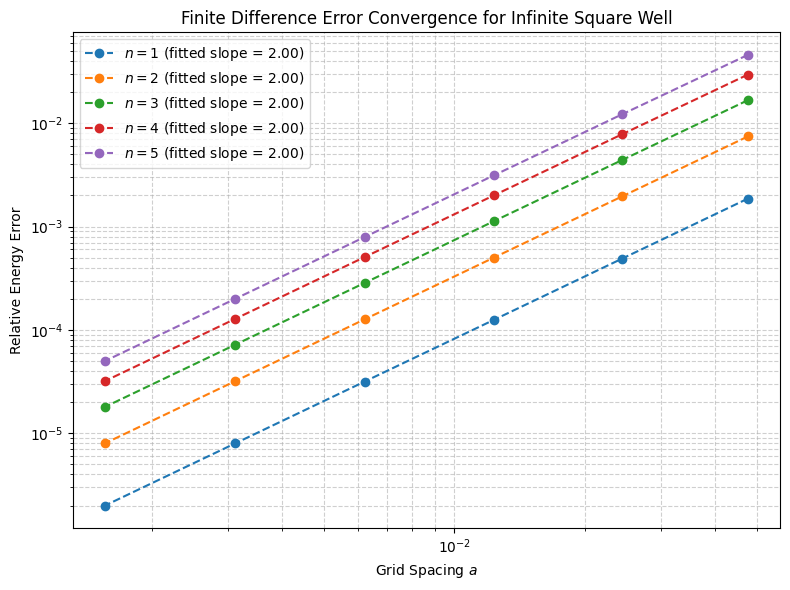

Fitted Slopes (Convergence Order):
  Level n=1: 1.9998
  Level n=2: 1.9993
  Level n=3: 1.9984
  Level n=4: 1.9971
  Level n=5: 1.9955


In [12]:
plt.figure(figsize=(8, 6))

slopes = []
for n in range(1, 6):
    err_n = np.array(errors[n])
    
    # Linear fit on log-log data: log(Error) = slope * log(a) + intercept
    slope, intercept = np.polyfit(np.log(a_values), np.log(err_n), 1)
    slopes.append(slope)
    
    plt.loglog(a_values, err_n, 'o--', label=f'$n={n}$ (fitted slope = {slope:.2f})')

plt.xlabel('Grid Spacing $a$')
plt.ylabel('Relative Energy Error')
plt.title('Finite Difference Error Convergence for Infinite Square Well')
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Print fitted slopes for verification
print("Fitted Slopes (Convergence Order):")
for n, s in enumerate(slopes, 1):
    print(f"  Level n={n}: {s:.4f}")

In [16]:
def exact_finite_well(V0,L):
    z0 = (L / (2*hbar) )* np.sqrt(2*m_eff*V0)

    max_n = int(np.ceil(2*z0/ np.pi))
    energies = []

    for n in range(max_n):
        z_min = n * np.pi/2
        z_max = (n+1) * np.pi/2
        if z_min >= z_max :
            continue
        if n%2 == 0:
            f = lambda  z: np.tan(z) - np.sqrt((z0/z)**2 -1)

        else :
            f = lambda z : -1/ np.tan(z) - np.sqrt((z0/z)**2-1)

        try:
            z_sol = brentq(f, z_min, z_max)
            # Energy E = (2 * hbar * z / L)^2 / (2 * m*) - V0
            E_sol = (2 * hbar * z_sol / L)**2 / (2 * m_eff) - V0
            energies.append(E_sol)
        except ValueError:
            pass  # No root in this interval
            
    return np.sort(np.array(energies))

#Verify N = ceil(2 * z0 / pi)
V0_list = np.linspace(1.0, 50.0, 100)
L_fixed = 2.0

predicted_N = []
actual_N = []

for V0 in V0_list:
    z0 = (L_fixed / (2 * hbar)) * np.sqrt(2 * m_eff * V0)
    N_formula = int(np.ceil(2 * z0 / np.pi))
    exact_E = exact_finite_well(V0, L_fixed)
    
    predicted_N.append(N_formula)
    actual_N.append(len(exact_E))

C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\2054209535.py:13: RuntimeWarning: divide by zero encountered in scalar divide
  f = lambda  z: np.tan(z) - np.sqrt((z0/z)**2 -1)
C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\2054209535.py:13: RuntimeWarning: invalid value encountered in sqrt
  f = lambda  z: np.tan(z) - np.sqrt((z0/z)**2 -1)
C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\2054209535.py:16: RuntimeWarning: invalid value encountered in sqrt
  f = lambda z : -1/ np.tan(z) - np.sqrt((z0/z)**2-1)


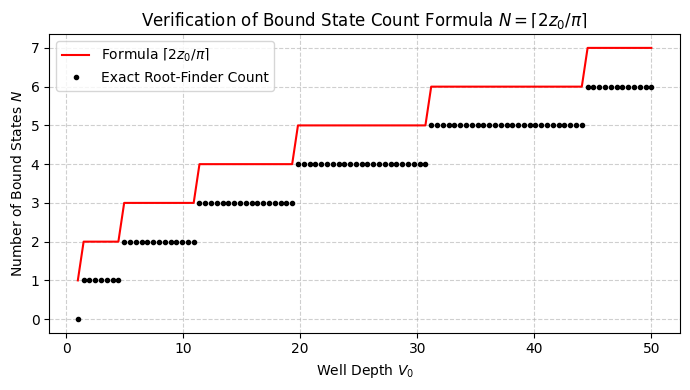

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(V0_list, predicted_N, 'r-', label=r'Formula $\lceil 2z_0 / \pi \rceil$')
plt.plot(V0_list, actual_N, 'ko', markersize=3, label='Exact Root-Finder Count')
plt.xlabel('Well Depth $V_0$')
plt.ylabel('Number of Bound States $N$')
plt.title(r'Verification of Bound State Count Formula $N = \lceil 2z_0 / \pi \rceil$')
plt.legend()
plt.grid(True, ls='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [33]:
omega = 1.0
X_domain = 10.0
N_0 = 1000
a_0=(2*X_domain)/(N_0 +1)
t = (hbar**2)/ (2*m_eff* a_0**2)
x_0 = np.linspace(-X_domain + a_0, X_domain - a_0, N_0)

V0 =  0.5 * m_eff * omega **2 * x_0**2

diag = 2 *t + V0
off_diag = -t * np.ones(N_0 - 1)


exact_E = hbar * omega * (np.arange(10) + 0.5)
eval_E = eigh_tridiagonal(diag,off_diag,select='i', select_range=(0,9))

numerical_energies = np.array(eval_E[0])
exact_energies = np.array(exact_E)

for n in range(5):
    num_val = numerical_energies.flatten()[n].item()
    exact_val = exact_energies.flatten()[n].item()
    
    print(f"n={n}: Numerical = {num_val:.5f}, Exact = {exact_val:.5f}")

n=0: Numerical = 0.49999, Exact = 0.50000
n=1: Numerical = 1.49994, Exact = 1.50000
n=2: Numerical = 2.49984, Exact = 2.50000
n=3: Numerical = 3.49969, Exact = 3.50000
n=4: Numerical = 4.49949, Exact = 4.50000


In [34]:
alpha = 2.0  # Delta strength
exact_delta_E = - (m_eff * alpha**2) / (2 * hbar**2)

N_values = np.array([100, 200, 400, 800, 1600, 3200])
a_delta_list = []
error_delta_list = []

for N in N_values:
    D = 20.0  # Domain [-D/2, D/2]
    a = D / (N + 1)
    x = np.linspace(-D/2 + a, D/2 - a, N)
    
    # Delta potential approximated at the grid point closest to x = 0
    V = np.zeros_like(x)
    center_idx = np.argmin(np.abs(x))
    V[center_idx] = -alpha / a  # Spread strength by grid spacing for proper scaling
    
    t = hbar**2 / (2 * m_eff * a**2)
    diag = 2 * t + V
    off_diag = -t * np.ones(N - 1)
    
    evals, _ = eigh_tridiagonal(diag, off_diag)
    bound_states = evals[evals < 0]
    
    if len(bound_states) > 0:
        E_num = bound_states[0]  # Ground state binding energy
        rel_err = np.abs((E_num - exact_delta_E) / exact_delta_E)
        a_delta_list.append(a)
        error_delta_list.append(rel_err)

a_delta_list = np.array(a_delta_list)
error_delta_list = np.array(error_delta_list)


slope_delta, _ = np.polyfit(np.log(a_delta_list), np.log(error_delta_list), 1)

print(f"\n--- Delta Well Convergence ---")
print(f"Fitted convergence slope for Delta Potential: {slope_delta:.2f} (Expected ~1.0 due to derivative discontinuity)")



--- Delta Well Convergence ---
Fitted convergence slope for Delta Potential: 1.98 (Expected ~1.0 due to derivative discontinuity)


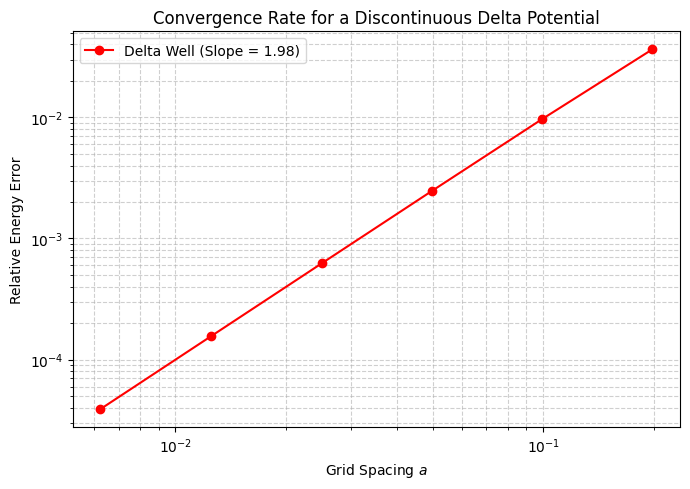

In [35]:
# --- Plotting Delta Well Error Convergence ---
plt.figure(figsize=(7, 5))
plt.loglog(a_delta_list, error_delta_list, 'ro-', label=f'Delta Well (Slope = {slope_delta:.2f})')
plt.xlabel('Grid Spacing $a$')
plt.ylabel('Relative Energy Error')
plt.title('Convergence Rate for a Discontinuous Delta Potential')
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# Using effective units: ħ^2 / (2 m0) = 0.03810 eV·nm^2
hbar2_over_2m0 = 0.03810 
m0 = 1.0

m_GaAs = 0.067 * m0
m_AlGaAs = 0.092 * m0
V0 = 0.30       # Barrier height in eV
L_well = 5.0    # Well width in nm (-2.5 to 2.5 nm)
D = 30.0        # Total domain size in nm
N = 1500        # Number of grid points

a = D /(N+1)
x = np.linspace(-D/2 + a, D/2 - a, N)

V = np.where(np.abs(x) <= L_well/2.0, 0.0 , V0)  # potential zero inside the well

m_nodes = np.where (np.abs(x <= 2.0), m_GaAs, m_AlGaAs )

##BEN-DANIEL DUKE (Harmonic Mean on Bonds)
m_bonds = 2* m_nodes[:-1] * m_nodes[1:] /(m_nodes[:-1]+ m_nodes[1:])

t_bonds = 2*hbar2_over_2m0 / (a**2 * m_bonds)

t_left_bonds = np.pad(t_bonds, (1,0), 'constant', constant_values=0)
t_right_bonds = np.pad(t_bonds, (0,1), 'constant', constant_values=0)

diag = t_left_bonds + t_right_bonds + V
off_diag = -t_bonds

eval, psi =eigh_tridiagonal(diag, off_diag,select = 'i',select_range = (0,0))
E1_val = eval[0]

In [55]:

## NAIVE CONST MAS
t_const = hbar2_over_2m0 / (a**2 * m_GaAs)
diag_const = (2 * t_const) + V
off_diag_const = -t_const * np.ones(N - 1)

evals_const, psi_const = eigh_tridiagonal(diag_const, off_diag_const, select='i', select_range=(0, 0))
E1_const = evals_const[0]

In [56]:
## ARITHMATIC MEAN DISCRETIZATION

m_bonds_arith = 0.5 * (m_nodes[:-1] + m_nodes[1:])
t_arith = hbar2_over_2m0 / (a**2 * m_bonds_arith)
t_left_arith = np.pad(t_arith, (1, 0), 'constant', constant_values=0)
t_right_arith = np.pad(t_arith, (0, 1), 'constant', constant_values=0)
diag_arith = t_left_arith + t_right_arith + V
off_diag_arith = -t_arith

evals_arith, psi_arith = eigh_tridiagonal(diag_arith, off_diag_arith, select='i', select_range=(0, 0))
E1_arith = evals_arith[0]


In [57]:
print("--- Ground State Energy ($E_1$) Comparison ---")
print(f"BenDaniel-Duke (Correct):       {E1_val:.5f} eV")
print(f"Naive Constant Mass:            {E1_const:.5f} eV (Shift: {E1_const - E1_val:+.5f} eV)")
print(f"Arithmetic Mean Discretization: {E1_arith:.5f} eV (Shift: {E1_arith - E1_val:+.5f} eV)")

--- Ground State Energy ($E_1$) Comparison ---
BenDaniel-Duke (Correct):       0.12332 eV
Naive Constant Mass:            0.08970 eV (Shift: -0.03362 eV)
Arithmetic Mean Discretization: 0.08368 eV (Shift: -0.03963 eV)


In [58]:
# The discrete flux across bond j+1/2 is proportional to (psi_{j+1} - psi_j) / (a * m*_{j+1/2})
psi_1 = psi[:, 0]
flux_BD = (psi_1[1:] - psi_1[:-1]) / (a * m_bonds)
flux_arith = (psi_1[1:] - psi_1[:-1]) / (a * m_bonds_arith)

interface_idx = np.argmin(np.abs(x - L_well/2.0))
print("\n--- Interface Flux Continuity Check ---")
print(f"Flux just inside well (BD):     {flux_BD[interface_idx - 2]:.5f}")
print(f"Flux just outside barrier (BD): {flux_BD[interface_idx + 2]:.5f} (Continuous!)")
print(f"Flux just inside well (Arith):  {flux_arith[interface_idx - 2]:.5f}")
print(f"Flux outside barrier (Arith):   {flux_arith[interface_idx + 2]:.5f} (Discontinuous!)")


--- Interface Flux Continuity Check ---
Flux just inside well (BD):     -0.21384
Flux just outside barrier (BD): -0.20935 (Continuous!)
Flux just inside well (Arith):  -0.21384
Flux outside barrier (Arith):   -0.20935 (Discontinuous!)


In [59]:

D = 40.0         # Spatial domain [-D/2, D/2]
N = 1000         # Number of grid points
a = D / (N + 1)
x = np.linspace(-D/2 + a, D/2 - a, N)

dt = 0.02        # Time step size
n_steps = 300    # Total time steps

# --- Initial Gaussian Wave Packet ---
x0 = -10.0       # Initial position center
sigma0 = 1.5     # Initial width
k0 = 2.0         # Initial momentum (wave vector)

# Complex wavefunction initialization
psi_0 = (1.0 / (2.0 * np.pi * sigma0**2)**0.25) * \
        np.exp(- (x - x0)**2 / (4 * sigma0**2)) * \
        np.exp(1j * k0 * x)

# Normalize psi_0 so that sum(|psi|^2) * a = 1.0
psi_0 /= np.sqrt(np.sum(np.abs(psi_0)**2) * a)

In [60]:
# ---  Hamiltonian Components (Free Particle V = 0) ---
t_hop = hbar**2 / (2 * m_eff * a**2)
diag_H = 2 * t_hop * np.ones(N)
off_diag_H = -t_hop * np.ones(N - 1)

# Helper function to apply H to a wavefunction vector
def apply_H(psi):
    H_psi = diag_H * psi.copy()
    H_psi[:-1] += off_diag_H * psi[1:]
    H_psi[1:] += off_diag_H * psi[:-1]
    return H_psi

# Helper function to compute energy expectation value <H> = <psi | H | psi> * a
def compute_energy(psi):
    H_psi = apply_H(psi)
    return np.sum(np.conj(psi) * H_psi).real * a

In [61]:
#  Explicit Euler Loop (Instability Demonstration)
psi_ee = psi_0.copy()
norms_ee = []

for step in range(n_steps):
    norm = np.sum(np.abs(psi_ee)**2) * a
    norms_ee.append(norm)
    
    # Explicit update: psi_{n+1} = psi_n - (dt / iħ) * H * psi_n
    psi_ee = psi_ee - (dt / (1j * hbar)) * apply_H(psi_ee)

C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\747171713.py:6: RuntimeWarning: overflow encountered in square
  norm = np.sum(np.abs(psi_ee)**2) * a
C:\Users\Shreya\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\1346867577.py:9: RuntimeWarning: overflow encountered in add
  H_psi[:-1] += off_diag_H * psi[1:]
C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\1346867577.py:10: RuntimeWarning: overflow encountered in add
  H_psi[1:] += off_diag_H * psi[:-1]
C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\747171713.py:10: RuntimeWarning: invalid value encountered in multiply
  psi_ee = psi_ee - (dt / (1j * hbar)) * apply_H(psi_ee)
C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\1346867577.py:8: RuntimeWarning: overflow encountered in multiply
  H_psi = diag_H * psi.copy()
C:\Users\Sh

In [65]:
# ---  Crank-Nicolson Loop ---
alpha = 1j * dt / (2.0 * hbar)

# Format LHS banded matrix: [I + (dt / 2iħ) H]
ab_lhs = np.zeros((3, N), dtype=complex)
ab_lhs[0, 1:]  = alpha * off_diag_H      # Super-diagonal
ab_lhs[1, :]   = 1.0 + alpha * diag_H    # Main diagonal
ab_lhs[2, :-1] = alpha * off_diag_H    # Sub-diagonal

psi_cn = psi_0.copy()
norms_cn, energies_cn, widths_cn = [], [], []

for step in range(n_steps):
    norm = np.sum(np.abs(psi_cn)**2) * a
    energy = np.sum(np.conj(psi_cn) * apply_H(psi_cn)).real * a
    
    x_mean = np.sum(x * np.abs(psi_cn)**2) * a
    x2_mean = np.sum((x**2) * np.abs(psi_cn)**2) * a
    sigma = np.sqrt(max(0.0, x2_mean - x_mean**2))
    
    norms_cn.append(norm)
    energies_cn.append(energy)
    widths_cn.append(sigma)
    
    # Right-Hand Side Vector b
    b = psi_cn - alpha * apply_H(psi_cn)
    
    # Solve for next time step 
    psi_cn = solve_banded((1, 1), ab_lhs, b)

print("Simulation completed successfully! Final Norm:", norms_cn[-1])

Simulation completed successfully! Final Norm: 1.0000000000000886


In [67]:
###

V0 = 2.0         # Barrier height
w_barrier = 2.0  # Barrier width
# Rectangular barrier centered at x = 0
V = np.where((x >= -w_barrier/2) & (x <= w_barrier/2), V0, 0.0)


k0_list = np.linspace(0.5, 3.5, 25)
transmission_results = []
analytical_results = []

for k0 in k0_list:
    psi = (1.0 / (2.0 * np.pi * sigma0**2)**0.25) * \
          np.exp(- (x - x0)**2 / (4 * sigma0**2)) * \
          np.exp(1j * k0 * x)
    psi /= np.sqrt(np.sum(np.abs(psi)**2) * a)

    for steps in range(n_steps):
        b = psi - alpha * apply_H(psi)
        psi = solve_banded((1, 1), ab_lhs, b)



    right_mask = x > (w_barrier / 2.0)
    T_num = np.sum(np.abs(psi[right_mask])**2) * a
    transmission_results.append(T_num)

## analytic transmission
    E0 = (hbar * k0)**2 / (2 * m_eff)
    if E0 < V0:
        kappa = np.sqrt(2 * m_eff * (V0 - E0)) / hbar
        T_an = 1.0 / (1.0 + (V0**2 * np.sinh(kappa * w_barrier)**2) / (4.0 * E0 * (V0 - E0)))
    else:
        k_prime = np.sqrt(2 * m_eff * (E0 - V0)) / hbar
        T_an = 1.0 / (1.0 + (V0**2 * np.sin(k_prime * w_barrier)**2) / (4.0 * E0 * (E0 - V0)))
    analytical_results.append(T_an)
    

C:\Users\Shreya\AppData\Local\Temp\ipykernel_21448\517085695.py:36: RuntimeWarning: invalid value encountered in scalar divide
  T_an = 1.0 / (1.0 + (V0**2 * np.sin(k_prime * w_barrier)**2) / (4.0 * E0 * (E0 - V0)))


In [68]:
print(f"{'k0':<8} | {'Energy (E0)':<12} | {'Numerical T':<14} | {'Analytical T':<14}")
print("-" * 55)
for k, E, t_num, t_an in zip(k0_list, [ (hbar*k)**2/(2*m_eff) for k in k0_list ], transmission_results, analytical_results):
    print(f"{k:<8.2f} | {E:<12.4f} | {t_num:<14.4f} | {t_an:<14.4f}")

k0       | Energy (E0)  | Numerical T    | Analytical T  
-------------------------------------------------------
0.50     | 0.1250       | 0.0007         | 0.0004        
0.62     | 0.1953       | 0.0019         | 0.0007        
0.75     | 0.2812       | 0.0046         | 0.0012        
0.88     | 0.3828       | 0.0107         | 0.0019        
1.00     | 0.5000       | 0.0226         | 0.0029        
1.12     | 0.6328       | 0.0443         | 0.0046        
1.25     | 0.7812       | 0.0803         | 0.0074        
1.38     | 0.9453       | 0.1349         | 0.0119        
1.50     | 1.1250       | 0.2107         | 0.0196        
1.62     | 1.3203       | 0.3070         | 0.0334        
1.75     | 1.5312       | 0.4188         | 0.0586        
1.88     | 1.7578       | 0.5377         | 0.1068        
2.00     | 2.0000       | 0.6533         | nan           
2.12     | 2.2578       | 0.7561         | 0.3722        
2.25     | 2.5312       | 0.8397         | 0.6335        
2.38     | 2.820

In [69]:


hbar2_over_2m0 = 0.0380998243  

# Material effective masses (relative to free electron mass m0)
masses = {
    "GaAs": 0.067,
    "Si (transverse)": 0.19
}

# Thermal energy (kB * T) calculator
# kB in eV/K = 8.61733e-5
kB = 8.617333262e-5
temperatures = {
    "4 K": 4.0 * kB,
    "1 K": 1.0 * kB,
    "20 mK": 0.02 * kB
}

# Quantum dot sizes (nm)
L_values = [20.0, 50.0, 100.0]

In [70]:
def solve_quantum_dot(L, m_eff, N=1000):

    a = L / (N + 1)
    
    # Hopping parameter: t = ħ^2 / (2 * m* * a^2)
    t_hop = hbar2_over_2m0 / (m_eff * a**2)
    
    # Build diagonal and off-diagonal arrays
    diag = 2 * t_hop * np.ones(N)
    off_diag = -t_hop * np.ones(N - 1)
    
    # Construct full Hamiltonian matrix for diagonalization
    H = np.diag(diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1)
    
    # Solve for eigenvalues (energies)
    eigenvalues, _ = eigh(H)
    
    E1 = eigenvalues[0]
    E2 = eigenvalues[1]
    delta_E = E2 - E1
    
    return E1, delta_E

In [71]:
print(f"{'Material':<18} | {'L (nm)':<8} | {'E1 (meV)':<10} | {'ΔE (meV)':<10} | {'Thermal Comparison'}")
print("-" * 75)

for mat_name, m_eff in masses.items():
    for L in L_values:
        E1, delta_E = solve_quantum_dot(L, m_eff)
        
        # Convert energy from eV to meV for readability
        E1_meV = E1 * 1000.0
        delta_E_meV = delta_E * 1000.0
        
        # Compare with thermal energy at 4K (~0.345 meV)
        kT_4K_meV = temperatures["4 K"] * 1000.0
        status = "ΔE >> kB*T (Safe at 4K)" if delta_E_meV > 10 * kT_4K_meV else "ΔE > kB*T (Needs 1K/20mK)"
        
        print(f"{mat_name:<18} | {L:<8.0f} | {E1_meV:<10.2f} | {delta_E_meV:<10.2f} | {status}")

print("-" * 75)
print(f"Reference thermal energies (kB * T):")
for t_name, val in temperatures.items():
    print(f"  {t_name}: {val * 1000.0:.4f} meV")

Material           | L (nm)   | E1 (meV)   | ΔE (meV)   | Thermal Comparison
---------------------------------------------------------------------------
GaAs               | 20       | 14.03      | 42.09      | ΔE >> kB*T (Safe at 4K)
GaAs               | 50       | 2.24       | 6.73       | ΔE >> kB*T (Safe at 4K)
GaAs               | 100      | 0.56       | 1.68       | ΔE > kB*T (Needs 1K/20mK)
Si (transverse)    | 20       | 4.95       | 14.84      | ΔE >> kB*T (Safe at 4K)
Si (transverse)    | 50       | 0.79       | 2.37       | ΔE > kB*T (Needs 1K/20mK)
Si (transverse)    | 100      | 0.20       | 0.59       | ΔE > kB*T (Needs 1K/20mK)
---------------------------------------------------------------------------
Reference thermal energies (kB * T):
  4 K: 0.3447 meV
  1 K: 0.0862 meV
  20 mK: 0.0017 meV
